In [2]:
import h2o
import numpy as np
import pandas as pd
import pyodbc
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
import warnings
import json
h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.391-b13, mixed mode)
  Starting server from C:\T0001\dse\Python\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp0cn40s0v
  JVM stdout: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp0cn40s0v\h2o_dan_larson_started_from_python.out
  JVM stderr: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp0cn40s0v\h2o_dan_larson_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,04 secs
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,2 months and 21 days
H2O_cluster_name:,H2O_from_python_dan_larson_6boc72
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.476 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


In [ ]:
saas = 'tenaya'

In [ ]:

dat = h2o.import_file(f"C:/MLAR_DATA/for_model/T0001/{saas}_model_ready.parquet")


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [ ]:
len(dat)

295476

In [ ]:
from h2o.estimators import H2OIsolationForestEstimator
fieldDictUnsupervised = ['audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name','record_signed','user_role','audit_count','seconds_to_process','volacity','distinct_users','distinct_result_names','STATUS_norm','OLD_STATUS_norm']


In [ ]:
isolation_model = H2OIsolationForestEstimator(model_id = f"{saas}_model1.hex", seed = 1234,categorical_encoding='one_hot_explicit')
isolation_model.train(training_frame = dat, x = fieldDictUnsupervised)

isolationforest Model Build progress: |██████████████████████████████████████████| (done) 100%


Model Details
=============
H2OIsolationForestEstimator : Isolation Forest
Model Key: tenaya_model1.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    50                 50                          26224                  8            8            7.84          1             70            37.12

ModelMetricsAnomaly: isolationforest
** Reported on train data. **

Anomaly Score: 6.259038026112552
Normalized Anomaly Score: 0.08491057510182982

Scoring History: 
    timestamp            duration    number_of_trees    mean_tree_path_length    mean_anomaly_score
--  -------------------  ----------  -----------------  -----------------------  --------------------
    2024-01-29 16:33:13  0.410 sec   0                  nan                      nan
    2024-01-29 16:33:13  0.629 sec   1                  6.93956                  0.00863381
    2024-01-29 16:33:13  0.832 sec   2                  6.94353                  0.0141183
    2024-01-29 16:33:13  1.150 sec   3                  6.93233                  0.0145012
    2024-01-29 16:33:14  1.351 sec   4                  6.90945                  0.0190632
    2024-01-29 16:33:14  1.564 sec   5                  6.86822                  0.0274545
    2024-01-29 16:33:14  1.771 sec   6                  6.86674                  0.0257931
    2024-01-29 16:33:14  1.983 sec   7                  6.85922                  0.0273731
    2024-01-29 16:33:14  2.210 sec   8                  6.85103                  0.0331051
    2024-01-29 16:33:15  2.441 sec   9                  6.83472                  0.0381415
    2024-01-29 16:33:15  2.653 sec   10                 6.84663                  0.0356681
    2024-01-29 16:33:15  2.861 sec   11                 6.85443                  0.0372384
    2024-01-29 16:33:15  3.083 sec   12                 6.83035                  0.0442563
    2024-01-29 16:33:16  3.310 sec   13                 6.83476                  0.0405295
    2024-01-29 16:33:16  3.581 sec   14                 6.83801                  0.040497
    2024-01-29 16:33:16  3.908 sec   15                 6.84191                  0.0401916
    2024-01-29 16:33:17  4.222 sec   16                 6.84128                  0.0384779
    2024-01-29 16:33:21  8.417 sec   36                 6.19995                  0.0682296
    2024-01-29 16:33:24  11.512 sec  50                 6.25904                  0.0849106

[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

In [ ]:
h2o.save_model(isolation_model,"C:/Users/dan.larson/Documents/MLAR/models/")

'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\tenaya_model1.hex'

In [ ]:
predictions = isolation_model.predict(dat)
predictions.head()

isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%


predict,mean_length
0.285714,5.5
0.275132,5.54
0.248677,5.64
0.164021,5.96
0.195767,5.84
0.169312,5.94
0.164021,5.96
0.169312,5.94
0.153439,6
0.275132,5.54


In [ ]:
saved_model = h2o.load_model('C:\\Users\\dan.larson\\Documents\\MLAR\\models\\seres_model1.hex')

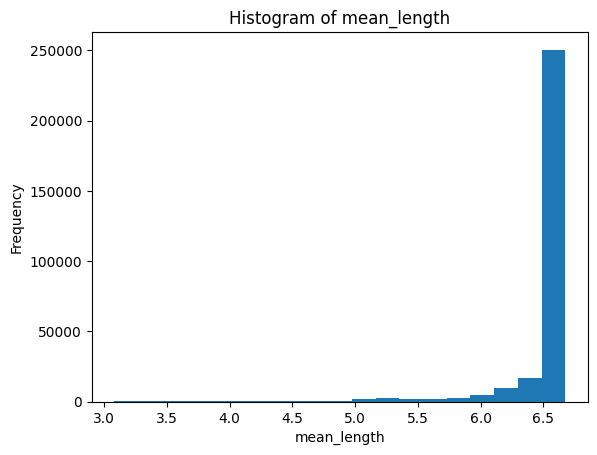

breaks,counts,mids_true,mids,widths
2.989,nan,nan,nan,nan
3.178,66,1.4,3.0835,0.189
3.367,111,1.5,3.2725,0.189
3.556,145,1.59,3.4615,0.189
3.745,216,1.69,3.6505,0.189
3.934,251,1.78,3.8395,0.189
4.123,296,1.88,4.0285,0.189
4.312,410,1.97,4.2175,0.189
4.501,395,2.07,4.4065,0.189
4.69,554,2.16,4.5955,0.189


In [ ]:
predictions["mean_length"].hist()

In [ ]:
other = saved_model.predict(dat)
other.head()

isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%


predict,mean_length
0.117241,6.06
0.110345,6.08
0.0965517,6.12
0.2,5.82
0.227586,5.74
0.213793,5.78
0.241379,5.7
0.213793,5.78
0.234483,5.72
0.0758621,6.18


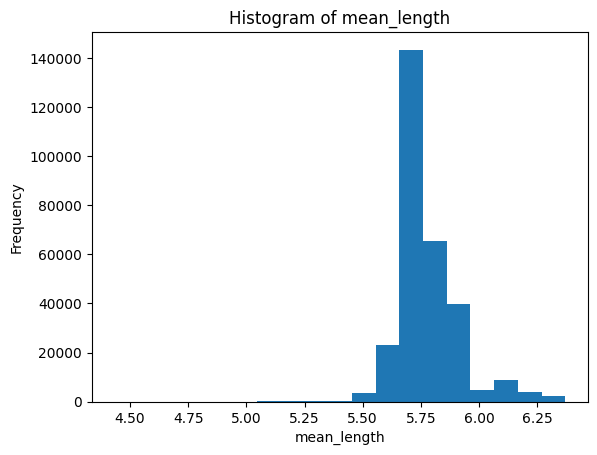

breaks,counts,mids_true,mids,widths
4.382,nan,nan,nan,nan
4.484,8,2.14,4.433,0.102
4.586,7,2.2,4.535,0.102
4.688,15,2.25,4.637,0.102
4.79,11,2.31,4.739,0.102
4.892,21,2.36,4.841,0.102
4.994,13,2.4,4.943,0.102
5.096,76,2.45,5.045,0.102
5.198,53,2.5,5.147,0.102
5.3,162,2.55,5.249,0.102


In [ ]:
other["mean_length"].hist()

In [ ]:
test = predictions.cbind(other)
test = test.as_data_frame()
test.quantile(0.10)

predict         0.037037
mean_length     6.040000
predict0        0.213793
mean_length0    5.520000
Name: 0.1, dtype: float64

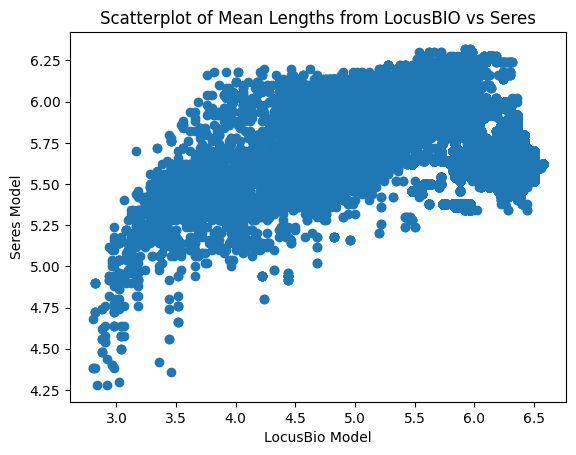

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame and 'variable1' and 'variable2' are the column names
plt.scatter(test['mean_length'], test['mean_length0'])
plt.xlabel('LocusBio Model')
plt.ylabel('Seres Model')
plt.title('Scatterplot of Mean Lengths from LocusBIO vs Seres')
plt.show()

In [ ]:
test['anomaly_1'] = np.where(test["mean_length"] < 6.04,"Yes", "No")
test['anomaly_2'] = np.where(test["mean_length0"] < 5.52,"Yes", "No")

In [ ]:
 pd.crosstab(test['anomaly_1'], test['anomaly_2'])

anomaly_2,No,Yes
anomaly_1,,
No,245084,21665
Yes,23430,5297


In [ ]:
test['anomaly_2'].value_counts()

anomaly_2
No     513954
Yes      9506
Name: count, dtype: int64

## Understanding the first model


In [ ]:
global_surrogate_data = dat[:, :]
global_surrogate_data["anomaly"] = (predictions["mean_length"] < 5.8).ifelse("Yes", "No")
global_surrogate_data["anomaly"].table()

anomaly,Count
No,496094
Yes,27366


In [ ]:
from h2o.estimators import H2ORandomForestEstimator

global_surrogate_dt = H2ORandomForestEstimator(model_id = "global_surrogate_decision_tree.hex", 
                                               ntrees = 1, max_depth = 3,
                                               sample_rate = 1, mtries = -1,
                                               categorical_encoding= 'one_hot_explicit')
global_surrogate_dt.train(training_frame = global_surrogate_data, x = fieldDictUnsupervised, y = "anomaly")

drf Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2ORandomForestEstimator : Distributed Random Forest
Model Key: global_surrogate_decision_tree.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    1                  1                           146                    3            3            3             7             7             7

ModelMetricsBinomial: drf
** Reported on train data. **

MSE: NaN
RMSE: NaN
LogLoss: NaN
Mean Per-Class Error: NaN
AUC: NaN
AUCPR: NaN
Gini: NaN

Scoring History: 
    timestamp            duration    number_of_trees    training_rmse    training_logloss    training_auc    training_pr_auc    training_lift    training_classification_error
--  -------------------  ----------  -----------------  ---------------  ------------------  --------------  -----------------  ---------------  -------------------------------
    2024-01-29 16:17:36  1.088 sec   0                  nan              nan                 nan             nan                nan              nan

Variable Importances: 
variable                     relative_importance    scaled_importance    percentage
---------------------------  ---------------------  -------------------  -------------------
audit_type.ReactivateSample  359.16943359375        1.0                  0.3827919649299977
volacity                     190.562744140625       0.5305650378817232   0.20309603337390345
audit_type.ModifySample      190.1365509033203      0.5293784301210339   0.20264180945758803
user_role._SUPERVISOR        143.5072021484375      0.39955293721000734  0.1529456539281707
distinct_users               36.90065002441406      0.10273883736485136  0.03932760142951492
seconds_to_process           18.012271881103516     0.05014979059013376  0.01919693688082521
audit_timestamp              0.0                    0.0                  0.0
audit_counter                0.0                    0.0                  0.0
trans_order                  0.0                    0.0                  0.0
audit_count                  0.0                    0.0                  0.0
---                          ---                    ---                  ---
OLD_STATUS_norm.C            0.0                    0.0                  0.0
OLD_STATUS_norm.E            0.0                    0.0                  0.0
OLD_STATUS_norm.I            0.0                    0.0                  0.0
OLD_STATUS_norm.M            0.0                    0.0                  0.0
OLD_STATUS_norm.N            0.0                    0.0                  0.0
OLD_STATUS_norm.P            0.0                    0.0                  0.0
OLD_STATUS_norm.R            0.0                    0.0                  0.0
OLD_STATUS_norm.U            0.0                    0.0                  0.0
OLD_STATUS_norm.X            0.0                    0.0                  0.0
OLD_STATUS_norm.missing(NA)  0.0                    0.0                  0.0
[71 rows x 4 columns]


[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

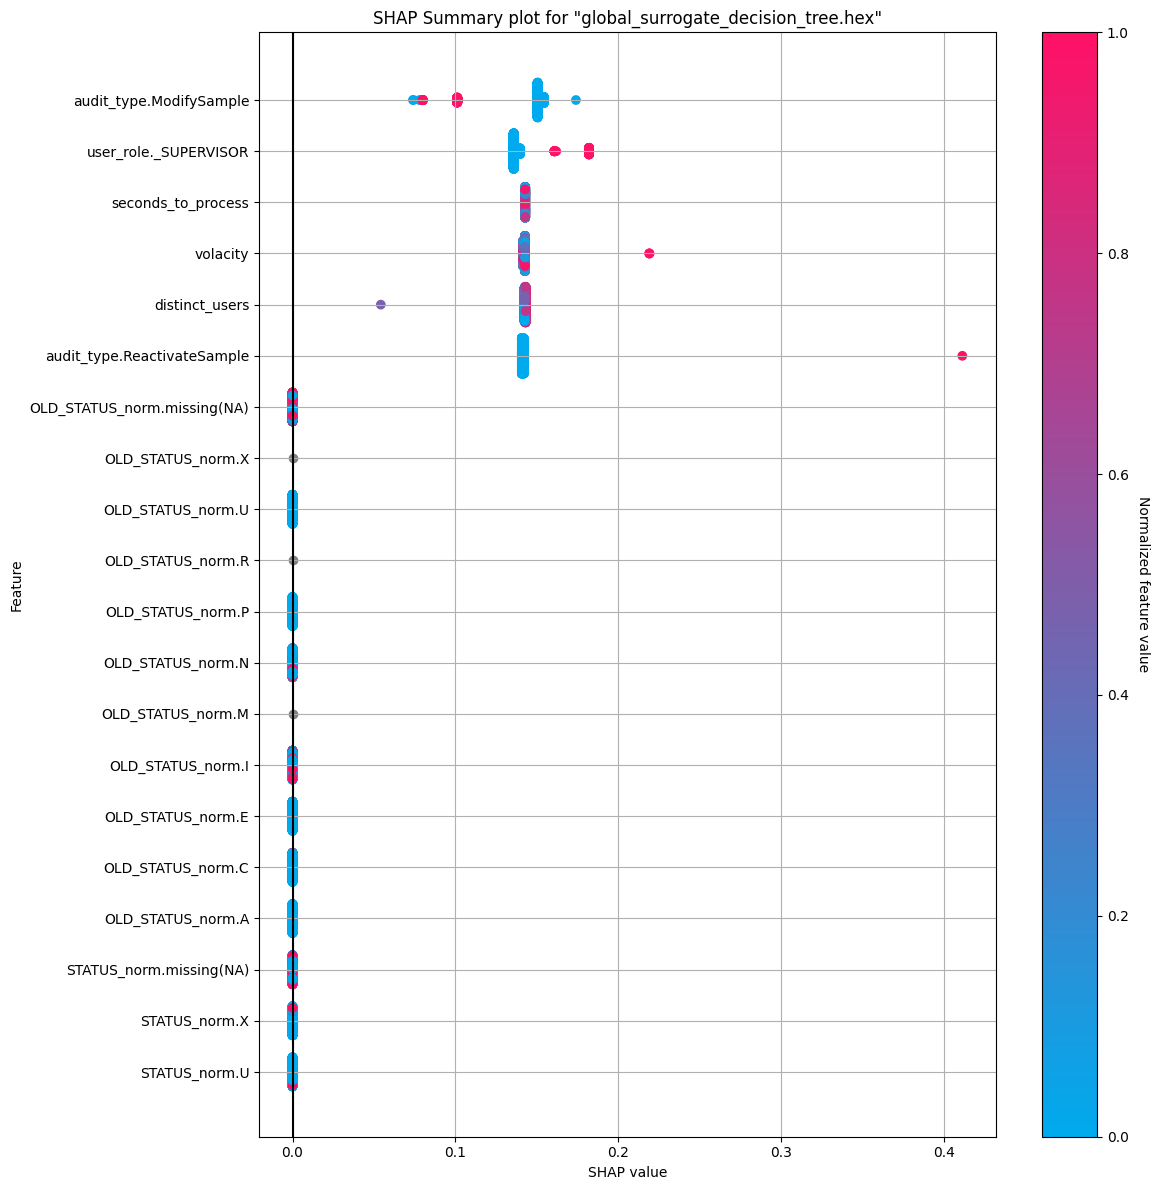

In [ ]:
global_surrogate_dt.shap_summary_plot(dat)

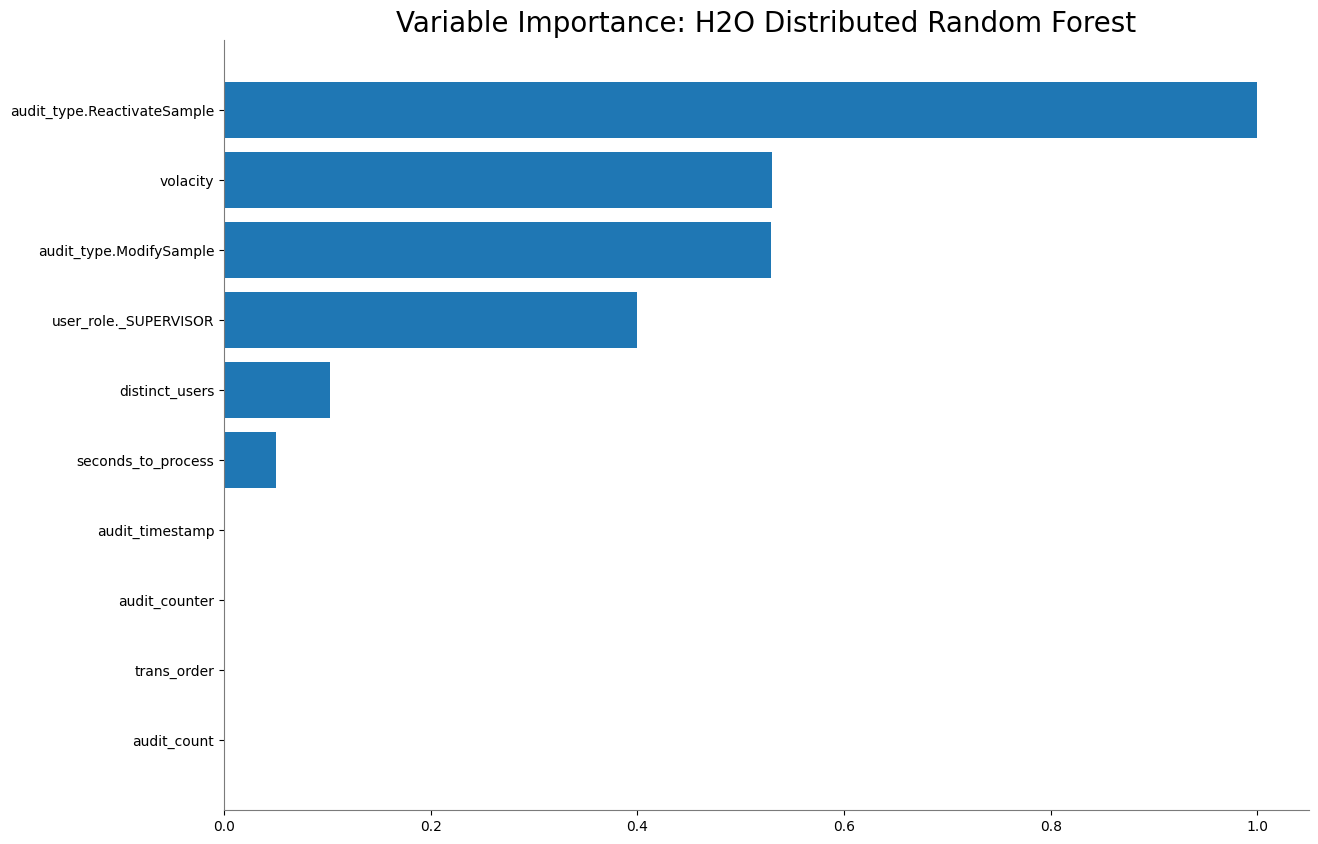

<Figure size 640x480 with 0 Axes>

In [ ]:
global_surrogate_dt.varimp_plot()

In [3]:
saas_customers = ['jaguar','locusbio','seres','tenaya']

my_df = pd.DataFrame()

for saas in ['jaguar']: 
    for saas_2 in ['jaguar','locusbio','seres','tenaya']: 
        if saas_2 == saas:
            print('same')
        else:
            dat = h2o.import_file(f"C:/MLAR_DATA/for_model/T0001/{saas}_model_ready.parquet")
            saas_2_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\{saas_2}_model1.hex')
            predictions = saas_2_model.predict(dat)
            saas_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\{saas}_model1.hex')
            other = saas_2_model.predict(dat)
            test = predictions.cbind(other)
            test = test.as_data_frame()
            ml_main = test['mean_length'].quantile(0.10)
            ml_other = test['mean_length0'].quantile(0.10)
            print(ml_other)
            test['anomaly_1'] = np.where(test["mean_length"]  < ml_main,"Yes", "No")
            test['anomaly_2'] = np.where(test["mean_length0"] < ml_other,"Yes", "No")
            
            ct = pd.crosstab(test['anomaly_1'], test['anomaly_2'])
            print(ct)
            new_rows_df = pd.DataFrame(ct)
            new_rows_df['model_trained'] = saas
            new_rows_df['data_tested'] = saas_2
            df = pd.concat([df, new_rows_df], ignore_index=True)


same


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
5.32


NameError: name 'ct' is not defined

In [1]:
df

NameError: name 'df' is not defined